In [ ]:
from itertools import islice
from pathlib import Path
from IORlib.ECL import UNRST_file, IX_input, Flow
from ior2ecl import Output
from IORlib.utils import flatten

cop = Path.home() / 'CoP_files'
root = cop/'input/Model_From_IXF/Model_From_IXF'
#root = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'

start, stop, step = 0, None, 1



1284743 1284780


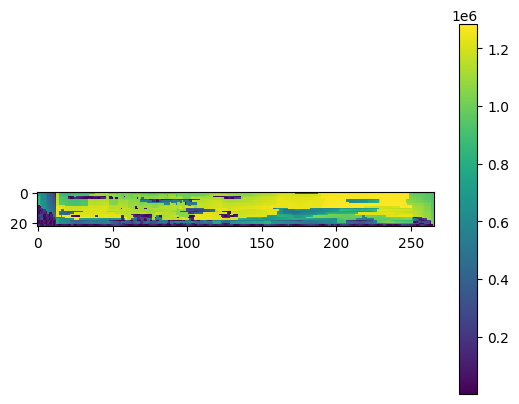

In [1]:
from itertools import islice
from math import prod
from pathlib import Path
import numpy as np
from IORlib.ECL import Flow, IX_input
import matplotlib.pyplot as pl

cop = Path.home() / 'CoP_files'
root = cop/'input/Model_From_IXF/Model_From_IXF'
root = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'

flow = Flow(root)
rate = next(islice(flow.rates(), 1, None, 1))

#in_degrees = np.where(rate.inflow[..., :-1] > 0, 1, 0)
#in_degrees = np.sum(np.where(rate.inflow[..., :-1] > 0, 1, 0), axis=-1)
#out_conn = np.where(rate.outflow[..., :-1, None] > 0, flow.connection_index(), -2)

#flow.connection_index()[0,0,0]
#flow.sort_blocks_by_flow2(rate)

dim = flow.unrst.dim()
#out_neigh = flow.neighbours_out(rate.block)
#in_neigh = flow.neighbours_in(rate.block)
sorted_blocks = flow.sort_blocks_by_flow2(rate) #, out_neigh, in_neigh)
print(len(sorted_blocks), prod(dim))
sort_order = np.zeros(dim, dtype=int)
sort_order[tuple(zip(*sorted_blocks))] = np.arange(len(sorted_blocks))
pl.imshow(sort_order[10,...].T, interpolation='none')
pl.colorbar()




In [10]:
[tuple(ind) for ind in np.argwhere(in_degrees == 0)]
#pos = (0,0,0)
#in_degrees.shape #[pos]
#[tuple(nb) for nb  in out_conn[pos] if nb[0] >= 0]

[(0, 0, 0),
 (0, 0, 1),
 (0, 0, 2),
 (0, 1, 0),
 (0, 1, 1),
 (0, 1, 2),
 (0, 2, 0),
 (0, 2, 1),
 (0, 2, 2),
 (0, 3, 0),
 (0, 3, 1),
 (0, 3, 2),
 (0, 4, 0),
 (0, 4, 1),
 (0, 4, 2),
 (0, 5, 0),
 (0, 5, 1),
 (0, 5, 2),
 (0, 6, 0),
 (0, 6, 1),
 (0, 6, 2),
 (0, 7, 0),
 (0, 7, 1),
 (0, 7, 2),
 (0, 8, 0),
 (0, 8, 1),
 (0, 8, 2),
 (0, 9, 0),
 (0, 9, 1),
 (0, 9, 2),
 (0, 10, 0),
 (0, 10, 1),
 (0, 10, 2),
 (0, 11, 0),
 (0, 11, 1),
 (0, 11, 2),
 (0, 12, 0),
 (0, 12, 1),
 (0, 12, 2),
 (0, 13, 0),
 (0, 13, 1),
 (0, 13, 2),
 (0, 14, 0),
 (0, 14, 1),
 (0, 14, 2),
 (0, 15, 0),
 (0, 15, 1),
 (0, 15, 2),
 (0, 16, 0),
 (0, 16, 1),
 (0, 16, 2),
 (0, 17, 0),
 (0, 17, 1),
 (0, 17, 2),
 (0, 18, 0),
 (0, 18, 1),
 (0, 18, 2),
 (0, 19, 0),
 (0, 19, 1),
 (0, 19, 2),
 (0, 20, 0),
 (0, 20, 1),
 (0, 20, 2),
 (0, 21, 0),
 (0, 21, 1),
 (0, 21, 2),
 (0, 22, 0),
 (0, 22, 1),
 (0, 22, 2),
 (0, 23, 0),
 (0, 23, 1),
 (0, 23, 2),
 (0, 24, 0),
 (0, 24, 1),
 (0, 24, 2),
 (1, 0, 0),
 (1, 0, 1),
 (1, 0, 2),
 (1, 1, 0),
 (1, 1,

In [ ]:
from IORlib.utils import roll_xyz

neigh_ind = np.concatenate(flow.neighbour_index(), axis=-2)
flow_out = np.concatenate((rate.block.outflow, roll_xyz(rate.block.inflow)), axis=-1)
flow_in = np.concatenate((rate.block.inflow, roll_xyz(rate.block.outflow)), axis=-1)
rate_out = np.concatenate((rate.block.rate_out, roll_xyz(rate.block.rate_in)), axis=-1)
rate_in = np.concatenate((rate.block.rate_in, roll_xyz(rate.block.rate_out)), axis=-1)
pos = (0,0,4)
#neigh_ind[pos], flow_out[pos], flow_in[pos]
neigh_out1 = flow.neighbours_out(rate.block)
neigh_out2 = np.where(flow_out[..., None], neigh_ind, -1)
#neigh_out1[pos], neigh_out2[pos]
#np.equal(neigh_out1, neigh_out2).all()
rate.block.rate_out[pos], rate_out[pos], neigh_out1[pos]

In [2]:
flow = Flow(root)
rate1 = next(islice(flow.rates(), 100, None, 1))
rate2 = next(islice(flow.rates2(), 100, None, 1))
#block = next(islice(flow.interblock_after2(), 100, None, 1))
pos = (0,0,4)
rate1.outflow[pos], rate2.outflow[pos]

(array([0.        , 0.        , 0.02146995, 0.        ]),
 array([-0.        , -0.        ,  0.        ,  0.        ,  0.        ,
         0.02146995,  0.        ]))